# Multilevel Analysis for Mental Effort, Task Difficulty, Perceived Performance Perception, and Team Gameplay Score based on Cardiac Measures

by Elvis Ortega-Ochoa

In [1]:
import sys
import subprocess

subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade", "pip", "ipywidgets", "jupyterlab_widgets"])
subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "pymer4",
    "rpy2",
    "polars",
    "great-tables",
    "joblib",
    "scikit-learn",
    "pyarrow",
    "bambi",
    "arviz",
    "matplotlib",
    "pandas",
    "numpy",
    "statsmodels",
    "openpyxl",
])

  Using cached pip-26.2.1-py3-none-any.whl.metadata (4.6 kB)
  Using cached ipywidgets-8.1.9-py3-none-any.whl.metadata (2.4 kB)
  Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl.metadata (20 kB)
  Using cached widgetsnbextension-4.0.16-py3-none-any.whl.metadata (1.6 kB)
Using cached pip-26.2.1-py3-none-any.whl (1.8 MB)
Using cached ipywidgets-8.1.9-py3-none-any.whl (140 kB)
Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl (217 kB)
Using cached widgetsnbextension-4.0.16-py3-none-any.whl (2.2 MB)
  Attempting uninstall: widgetsnbextension
    Found existing installation: widgetsnbextension 4.0.15
    Uninstalling widgetsnbextension-4.0.15:
      Successfully uninstalled widgetsnbextension-4.0.15
  Attempting uninstall: pip
    Found existing installation: pip 26.2
    Uninstalling pip-26.2:
      Successfully uninstalled pip-26.2
  Attempting uninstall: jupyterlab_widgets━━━━━━━━━━━━━━━━━━━━━━━━ 1/4 [pip]
    Found existing installation: jupyterlab_widgets 3.0.16━━━━ 1/4 [

0

Packages

In [3]:
import pandas as pd
import numpy as np
import bambi as bmb
import arviz as az
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import matplotlib.patches as patches
import statsmodels.api as sm
import pymer4.models as pm
import polars as pl
import ipywidgets as widgets
from pymer4.models import lmer as Lmer

Loading data

In [5]:
# Reading files and printing columns
hrv = pd.read_excel("../HRV_data_v3.xlsx", keep_default_na=False)     
dv = pd.read_excel("../CONT_dependent_variables_confidence_mental_effort_task_difficulty_E.xlsx", keep_default_na=False)

# Make a clean copy
hrv = hrv.copy()
me_td = dv.copy()

# Extract participantID and sensorID from hrvID
hrv["participantID"] = hrv["hrvID"].str.extract(r"^([^.]+)\.", expand=False)
hrv["sensorID"] = hrv["hrvID"].str.extract(r"\.([A-Z])-PPG", expand=False) * 2

# Merge the dataframes on groupID, participantID, and sensorID
dataset = hrv.merge(
    me_td,
    on=["groupID", "participantID", "sensorID"],
    how="inner"
)

# Rename columns for clarity
dataset = dataset.rename(columns={
    "ME1": "me",
    "TD1": "td",
    "PP1": "pp"
})

Reverse team gameplay score

In [6]:
# Build numeric uncertScore
dataset["uncertScore"] = pd.to_numeric(dataset["uncertScore"], errors="coerce")

# Reverse-coding, using the instrument's theoretical bounds, not the sample's
SCALE_MIN, SCALE_MAX = 1, 70  # instrument range
dataset["uncertScore"] = (SCALE_MIN + SCALE_MAX) - dataset["uncertScore"]


In [7]:
# Finalize data types
dataset["groupID"] = dataset["groupID"].astype("category")
#dataset["cf"] = pd.to_numeric(dataset["cf"], errors="coerce")
dataset["me"] = pd.to_numeric(dataset["me"], errors="coerce")
dataset["td"] = pd.to_numeric(dataset["td"], errors="coerce")
dataset["pp"] = pd.to_numeric(dataset["pp"], errors="coerce")

In [8]:
# Keep just variables needed
dat_model = dataset[["groupID", "participantID", "me", "td", "pp", "uncertScore", "realMean_HR_bpm", "realRMSSD_ms"]].copy()

## Mixed Linear Models

### Within/Between Descomposition

In [9]:

def add_within_between(df, raw_col, prefix):
    group_mean = df.groupby("groupID")[raw_col].transform("mean")
    within = df[raw_col] - group_mean
    between = group_mean - group_mean.mean()

    df[f"{prefix}_group_mean"] = group_mean
    df[f"{prefix}_within"] = within
    df[f"{prefix}_between"] = between

    return df

dat_model = add_within_between(dat_model, "realMean_HR_bpm", "hr")
dat_model = add_within_between(dat_model, "realRMSSD_ms", "rmssd")
dat_model = add_within_between(dat_model, "pp", "pp")
dat_model = add_within_between(dat_model, "me", "me")
dat_model = add_within_between(dat_model, "td", "td")

### Standarize predictor variables

In [10]:
dat_model["realMean_HR_bpm_z"] = (
    dat_model["realMean_HR_bpm"] - dat_model["realMean_HR_bpm"].mean()
) / dat_model["realMean_HR_bpm"].std()

dat_model["hr_within_z"] = (
    dat_model["hr_within"] - dat_model["hr_within"].mean()
) / dat_model["hr_within"].std()

dat_model["hr_between_z"] = (
    dat_model["hr_between"] - dat_model["hr_between"].mean()
) / dat_model["hr_between"].std()

dat_model["realRMSSD_ms_z"] = (
    dat_model["realRMSSD_ms"] - dat_model["realRMSSD_ms"].mean()
) / dat_model["realRMSSD_ms"].std()

dat_model["rmssd_within_z"] = (
    dat_model["rmssd_within"] - dat_model["rmssd_within"].mean()
) / dat_model["rmssd_within"].std()

dat_model["rmssd_between_z"] = (
    dat_model["rmssd_between"] - dat_model["rmssd_between"].mean()
) / dat_model["rmssd_between"].std()

dat_model["pp_z"] = (
    dat_model["pp"] - dat_model["pp"].mean()
) / dat_model["pp"].std()


dat_model["uncertScore_z"] = (
    dat_model["uncertScore"] - dat_model["uncertScore"].mean()
) / dat_model["uncertScore"].std()

dat_model["me_z"] = (
    dat_model["me"] - dat_model["me"].mean()
) / dat_model["me"].std()

dat_model["me_within_z"] = (
    dat_model["me_within"] - dat_model["me_within"].mean()
) / dat_model["me_within"].std()

dat_model["me_between_z"] = (
    dat_model["me_between"] - dat_model["me_between"].mean()
) / dat_model["me_between"].std()

dat_model["td_z"] = (
    dat_model["td"] - dat_model["td"].mean()
) / dat_model["td"].std()

dat_model["td_within_z"] = (
    dat_model["td_within"] - dat_model["td_within"].mean()
) / dat_model["td_within"].std()

dat_model["td_between_z"] = (
    dat_model["td_between"] - dat_model["td_between"].mean()
) / dat_model["td_between"].std()

dat_model.columns.tolist()

# Team-level dataset (one row per team, n = 29) for team gameplay score models
team_model = dat_model.drop_duplicates(subset="groupID").copy()

## Exploratory Data Analysis

In [11]:
cols_no_z = ["me", "td", "pp", "uncertScore", "realMean_HR_bpm", "realRMSSD_ms"]

# Labels to display
labels = {
    "me": "Mental effort",
    "me_z": "Mental effort Z-score",
    "td": "Task difficulty",
    "td_z": "Task difficulty Z-score",
    "pp": "Perceived indiv. performance",
    "pp_z": "Perceived indiv. performance Z-score",
    "uncertScore": "Team gameplay score",
    "uncertScore_z": "Team gameplay score Z-score",
    "realMean_HR_bpm": "Mean Heart Rate (bpm)",
    "realMean_HR_bpm_z": "Mean Heart Rate (bpm) Z-score",
    "hr_within_z": "Within-team Mean HR Z-score",
    "hr_between_z": "Between-team Mean HR Z-score",
    "realRMSSD_ms": "Root Mean Square of Successive Differences (RMSSD)",
    "realRMSSD_ms_z": "Root Mean Square of Successive Differences (RMSSD) Z-score",
    "rmssd_within_z": "Within-team RMSSD Z-score",
    "rmssd_between_z": "Between-team RMSSD Z-score"
}

# Basic summary
print("Missing values:")
print(dat_model[cols_no_z].isna().sum(), "\n")

print("Descriptive statistics:")
display(dat_model[cols_no_z].describe().T)

Missing values:
me                 0
td                 0
pp                 0
uncertScore        0
realMean_HR_bpm    0
realRMSSD_ms       0
dtype: int64 

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
me,87.0,6.402299,1.735135,3.0000,5.00000,6.0000,7.00000,10.0000
td,87.0,6.390805,1.787270,2.0000,5.00000,7.0000,8.00000,10.0000
pp,87.0,6.494253,1.764466,2.0000,5.00000,7.0000,8.00000,10.0000
uncertScore,87.0,33.482759,7.603338,11.0000,30.00000,34.0000,37.00000,46.0000
realMean_HR_bpm,87.0,-1.846626,11.973151,-70.3546,-3.14685,0.7487,2.59000,12.8109
realRMSSD_ms,87.0,14.252398,28.079521,-41.8620,1.30885,9.9379,20.87345,160.9357


Missing values:
me_z                 0
td_z                 0
pp_z                 0
uncertScore_z        0
realMean_HR_bpm_z    0
realRMSSD_ms_z       0
dtype: int64 

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
me_z,87.0,-1.065559e-16,1.0,-1.960827,-0.808179,-0.231855,0.344470,2.073442
td_z,87.0,1.528152e-16,1.0,-2.456711,-0.778173,0.340853,0.900365,2.019390
pp_z,87.0,-7.592905e-17,1.0,-2.547090,-0.846859,0.286629,0.853373,1.986861
uncertScore_z,87.0,-4.083579e-16,1.0,-2.956959,-0.458057,0.068028,0.462592,1.646282
realMean_HR_bpm_z,87.0,-3.605035e-17,1.0,-5.721800,-0.108595,0.216762,0.370548,1.224200
realRMSSD_ms_z,87.0,-1.276118e-17,1.0,-1.998410,-0.460960,-0.153653,0.235796,5.223853


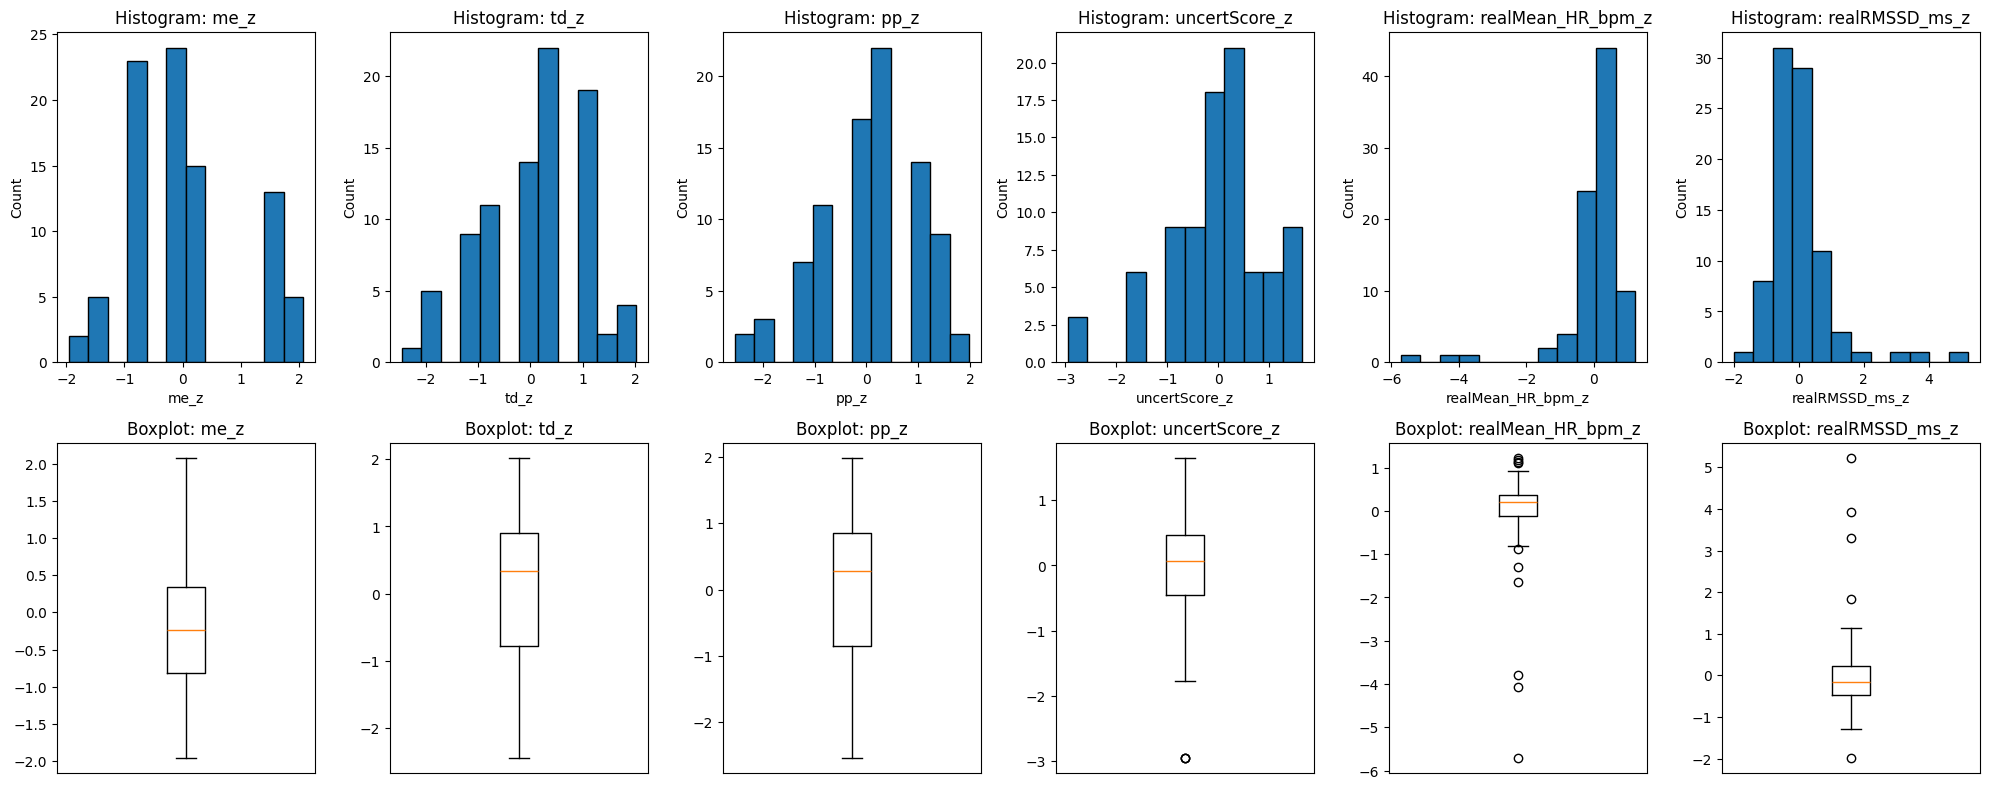

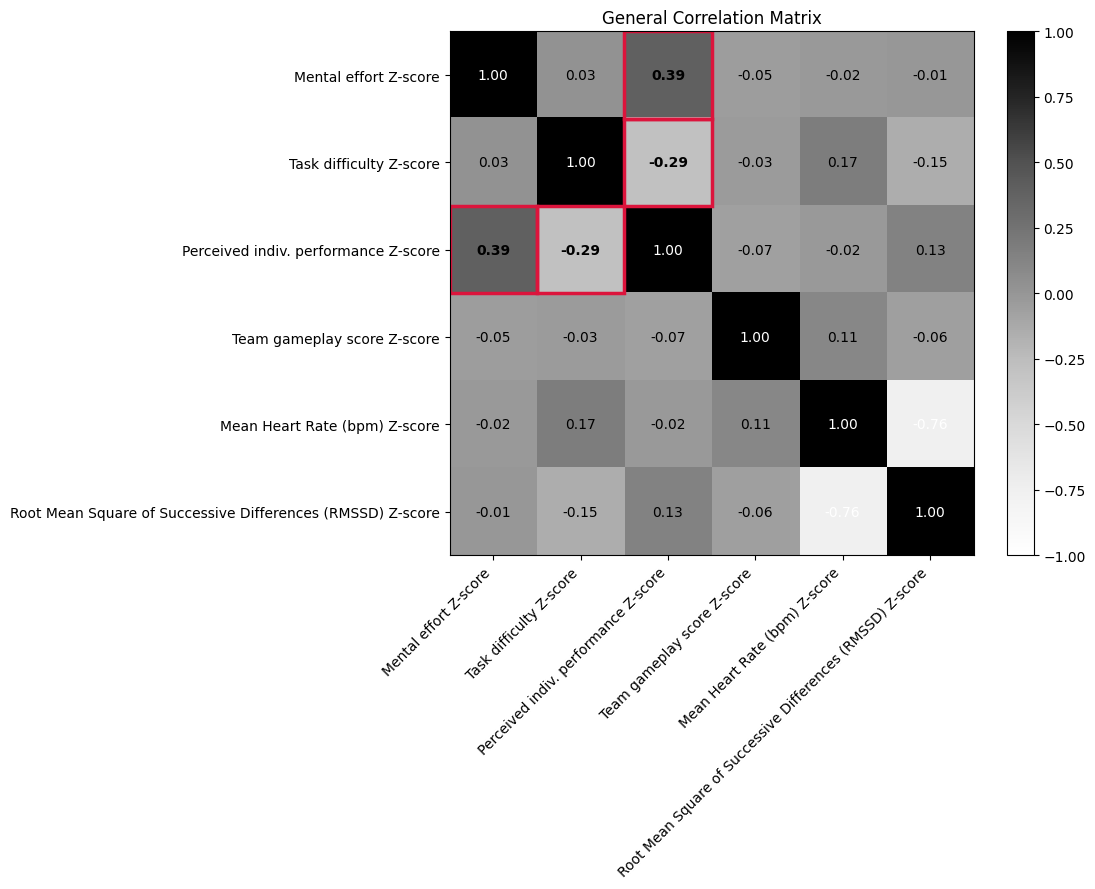

In [12]:
cols = ["me_z", "td_z", "pp_z", "uncertScore_z", "realMean_HR_bpm_z", "realRMSSD_ms_z"]

# Basic summary
print("Missing values:")
print(dat_model[cols].isna().sum(), "\n")

print("Descriptive statistics:")
display(dat_model[cols].describe().T)

# Distribution plots and boxplots
fig, axes = plt.subplots(2, len(cols), figsize=(20, 8))

for i, col in enumerate(cols):
    axes[0, i].hist(dat_model[col], bins=12, edgecolor="black")
    axes[0, i].set_title(f"Histogram: {col}")
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel("Count")

    axes[1, i].boxplot(dat_model[col], vert=True)
    axes[1, i].set_title(f"Boxplot: {col}")
    axes[1, i].set_xticks([])

plt.tight_layout()
plt.show()

# Correlation matrix
corr = dat_model[cols].corr()

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)

display_labels = [labels[col] for col in cols]

ax.set_xticks(range(len(display_labels)))
ax.set_yticks(range(len(display_labels)))
ax.set_xticklabels(display_labels, rotation=45, ha="right")
ax.set_yticklabels(display_labels)
ax.set_title("General Correlation Matrix")

threshold = 0.20
class MultiFocus:
    def __init__(self, items):
        self.items = set(items)
    def __eq__(self, other):
        return other in self.items

focus_var = MultiFocus(["me_z", "td_z"])

# Add correlation scores in each cell
for i in range(len(cols)):
    for j in range(len(cols)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) > 0.5 else "black"
        involves_focus = focus_var in (cols[i], cols[j])
        is_strong = abs(value) >= threshold and i != j and involves_focus
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                 color=text_color, fontweight="bold" if is_strong else "normal")
        if is_strong:
            rect = patches.Rectangle((j - 0.5, i - 0.5), 1, 1,
                                       linewidth=2.5, edgecolor="crimson", facecolor="none")
            ax.add_patch(rect)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [13]:
eda_df = dat_model.copy()

cols_within_between = ["me_z", "td_z", "pp_z", "uncertScore_z", "hr_within_z", "hr_between_z", "rmssd_within_z", "rmssd_between_z"]
cols_within = ["me_z", "td_z", "pp_z", "uncertScore_z", "hr_within_z", "rmssd_within_z"]
cols_between = ["me_z", "td_z", "pp_z", "uncertScore_z", "hr_between_z", "rmssd_between_z"]

Within-team Exploratory Data Analysis

Missing values:
me_z              0
td_z              0
pp_z              0
uncertScore_z     0
hr_within_z       0
rmssd_within_z    0
dtype: int64 

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
me_z,87.0,-1.065559e-16,1.0,-1.960827,-0.808179,-0.231855,0.344470,2.073442
td_z,87.0,1.528152e-16,1.0,-2.456711,-0.778173,0.340853,0.900365,2.019390
pp_z,87.0,-7.592905e-17,1.0,-2.547090,-0.846859,0.286629,0.853373,1.986861
uncertScore_z,87.0,-4.083579e-16,1.0,-2.956959,-0.458057,0.068028,0.462592,1.646282
hr_within_z,87.0,-1.308021e-17,1.0,-4.896501,-0.220500,0.063628,0.325923,2.455934
rmssd_within_z,87.0,1.531342e-17,1.0,-2.473687,-0.524082,-0.012081,0.411390,4.157529


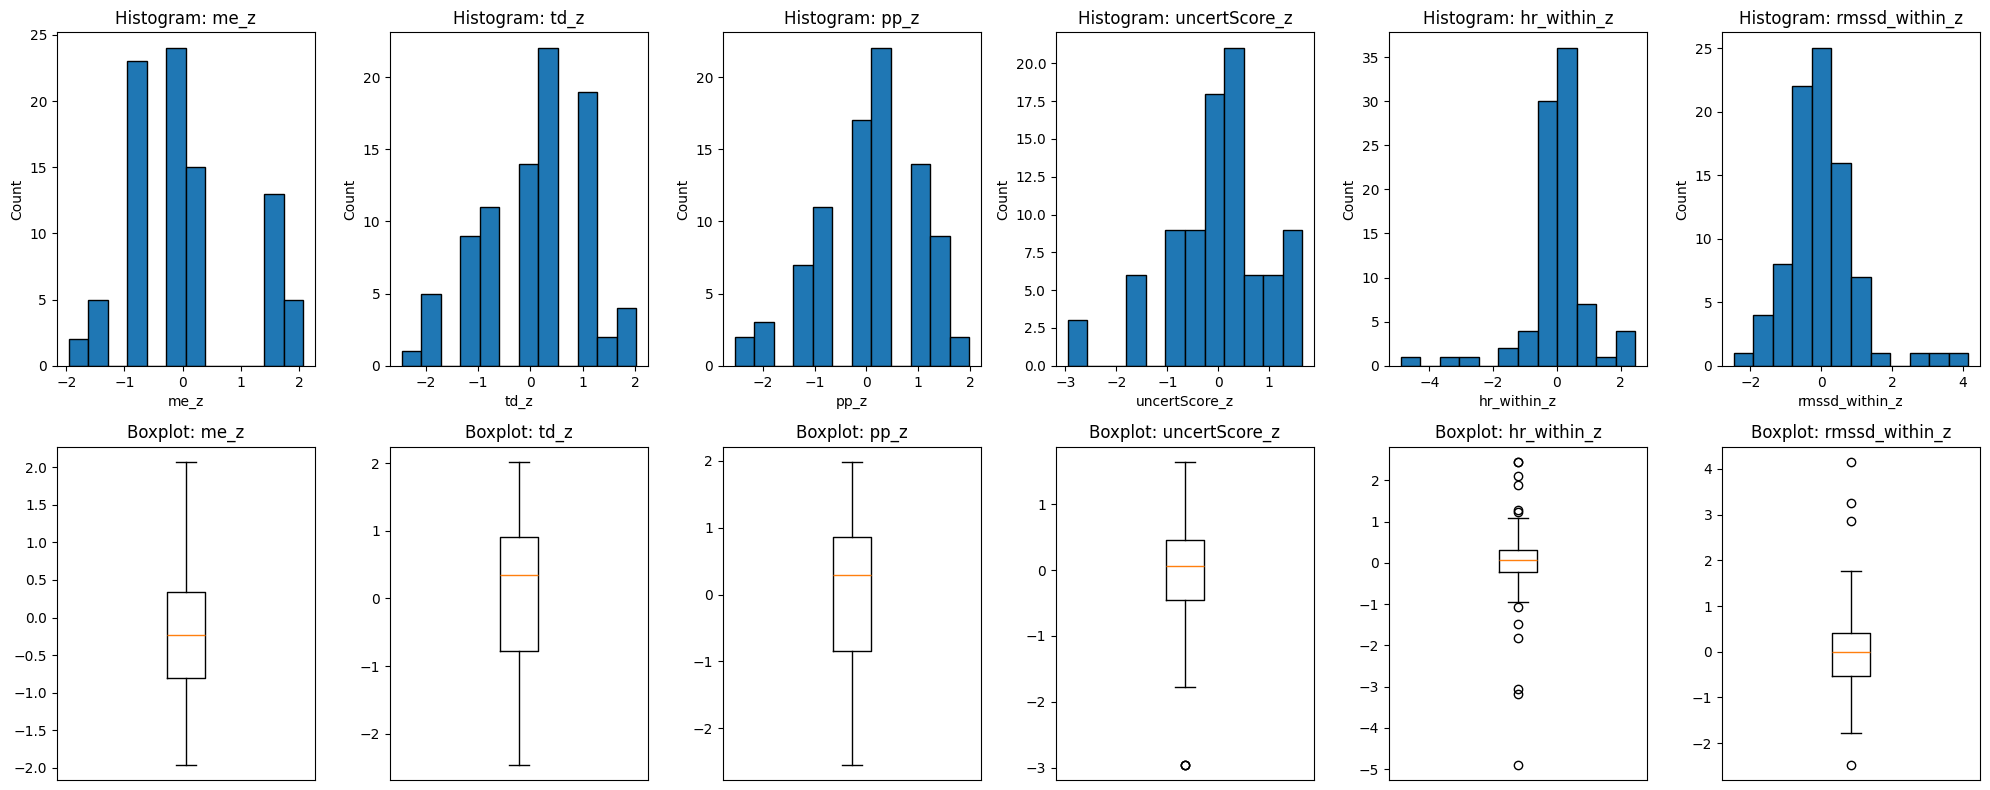

In [14]:
# Basic summary
print("Missing values:")
print(eda_df[cols_within].isna().sum(), "\n")

print("Descriptive statistics:")
display(eda_df[cols_within].describe().T)

# Distribution plots and boxplots
fig, axes = plt.subplots(2, len(cols_within), figsize=(20, 8))

for i, col in enumerate(cols_within):
    axes[0, i].hist(eda_df[col], bins=12, edgecolor="black")
    axes[0, i].set_title(f"Histogram: {col}")
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel("Count")

    axes[1, i].boxplot(eda_df[col], vert=True)
    axes[1, i].set_title(f"Boxplot: {col}")
    axes[1, i].set_xticks([])

plt.tight_layout()
plt.show()

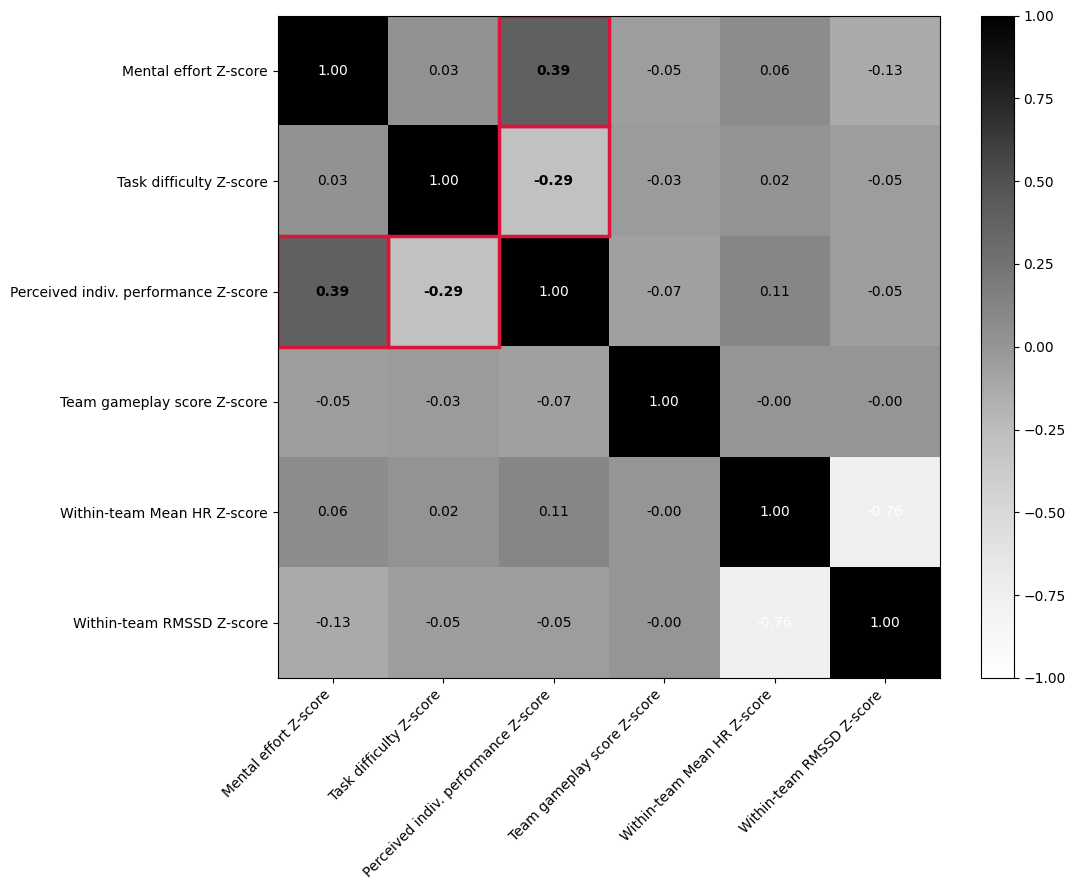

In [15]:
# Correlation matrix
corr = eda_df[cols_within].corr()

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)

display_labels = [labels[col] for col in cols_within]

ax.set_xticks(range(len(display_labels)))
ax.set_yticks(range(len(display_labels)))
ax.set_xticklabels(display_labels, rotation=45, ha="right")
ax.set_yticklabels(display_labels)

threshold = 0.20
class MultiFocus:
    def __init__(self, items):
        self.items = set(items)
    def __eq__(self, other):
        return other in self.items

focus_var = MultiFocus(["me_z", "td_z"])

for i in range(len(cols_within)):
    for j in range(len(cols_within)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) > 0.5 else "black"
        involves_focus = focus_var in (cols_within[i], cols_within[j])
        is_strong = abs(value) >= threshold and i != j and involves_focus
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                 color=text_color, fontweight="bold" if is_strong else "normal")
        if is_strong:
            rect = patches.Rectangle((j - 0.5, i - 0.5), 1, 1,
                                       linewidth=2.5, edgecolor="crimson", facecolor="none")
            ax.add_patch(rect)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

Between-team Exploratory Data Analysis

Missing values:
me_z               0
td_z               0
pp_z               0
uncertScore_z      0
hr_between_z       0
rmssd_between_z    0
dtype: int64 

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
me_z,87.0,-1.065559e-16,1.0,-1.960827,-0.808179,-0.231855,0.344470,2.073442
td_z,87.0,1.528152e-16,1.0,-2.456711,-0.778173,0.340853,0.900365,2.019390
pp_z,87.0,-7.592905e-17,1.0,-2.547090,-0.846859,0.286629,0.853373,1.986861
uncertScore_z,87.0,-4.083579e-16,1.0,-2.956959,-0.458057,0.068028,0.462592,1.646282
hr_between_z,87.0,-1.084701e-17,1.0,-2.981593,-0.100543,0.372596,0.592498,1.162034
rmssd_between_z,87.0,-6.380592e-18,1.0,-1.707508,-0.386674,-0.192074,0.270356,3.163902


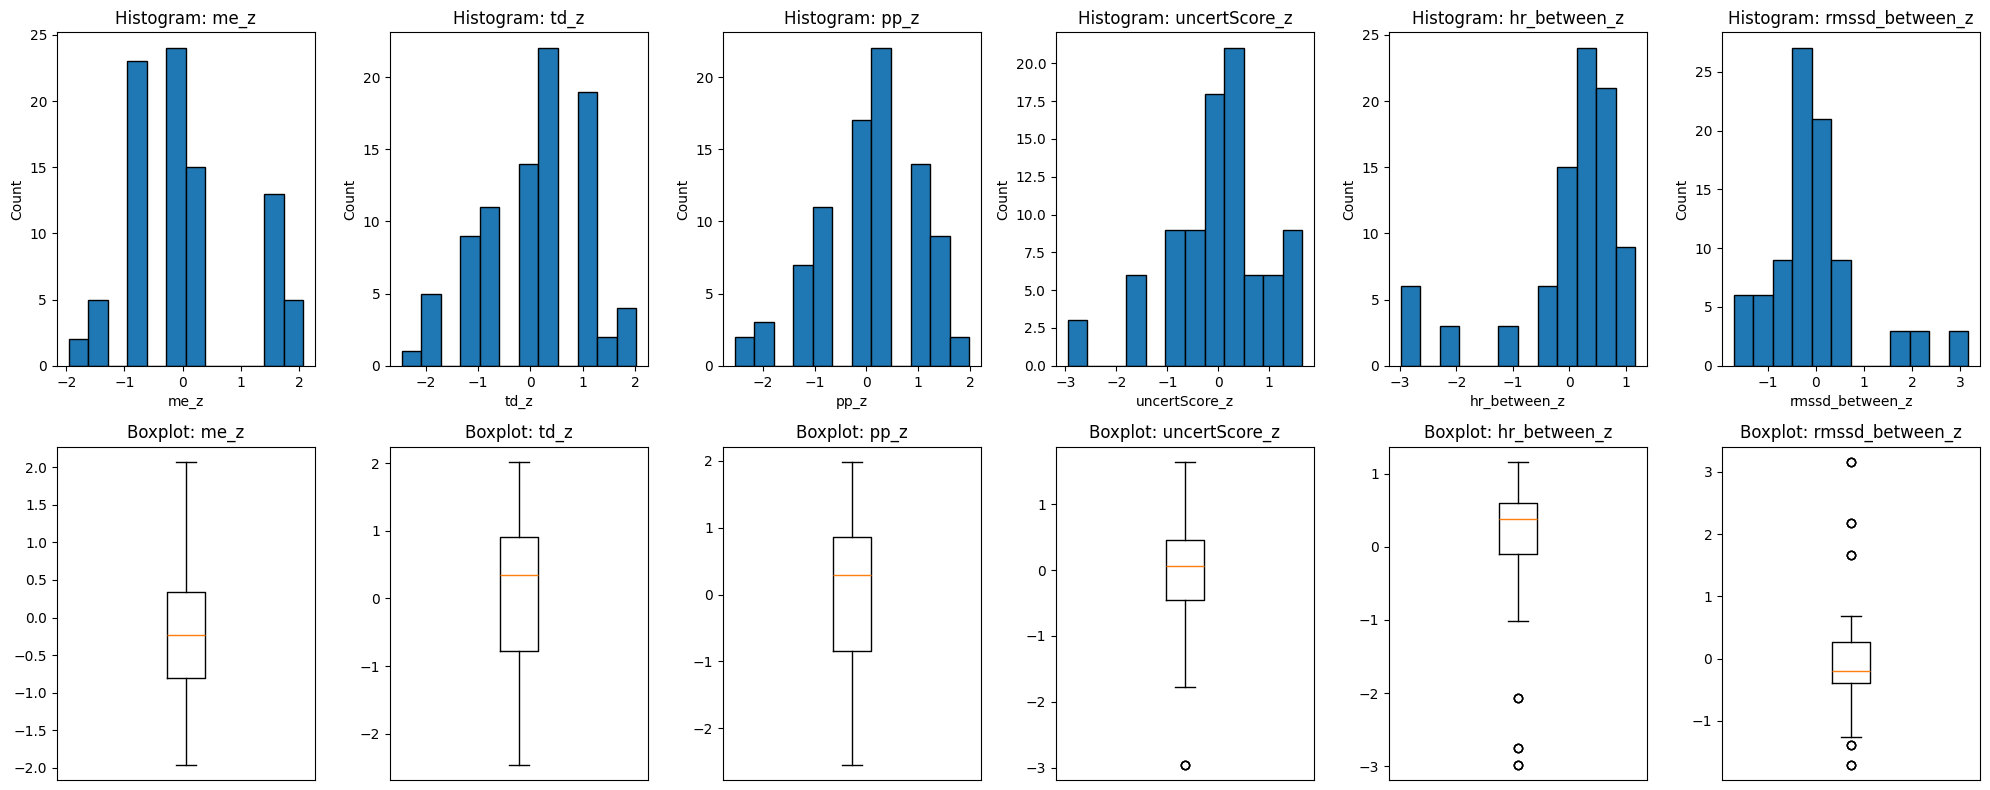

In [16]:
# Basic summary
print("Missing values:")
print(eda_df[cols_between].isna().sum(), "\n")

print("Descriptive statistics:")
display(eda_df[cols_between].describe().T)

# Distribution plots and boxplots
fig, axes = plt.subplots(2, len(cols_between), figsize=(20, 8))

for i, col in enumerate(cols_between):
    axes[0, i].hist(eda_df[col], bins=12, edgecolor="black")
    axes[0, i].set_title(f"Histogram: {col}")
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel("Count")

    axes[1, i].boxplot(eda_df[col], vert=True)
    axes[1, i].set_title(f"Boxplot: {col}")
    axes[1, i].set_xticks([])

plt.tight_layout()
plt.show()

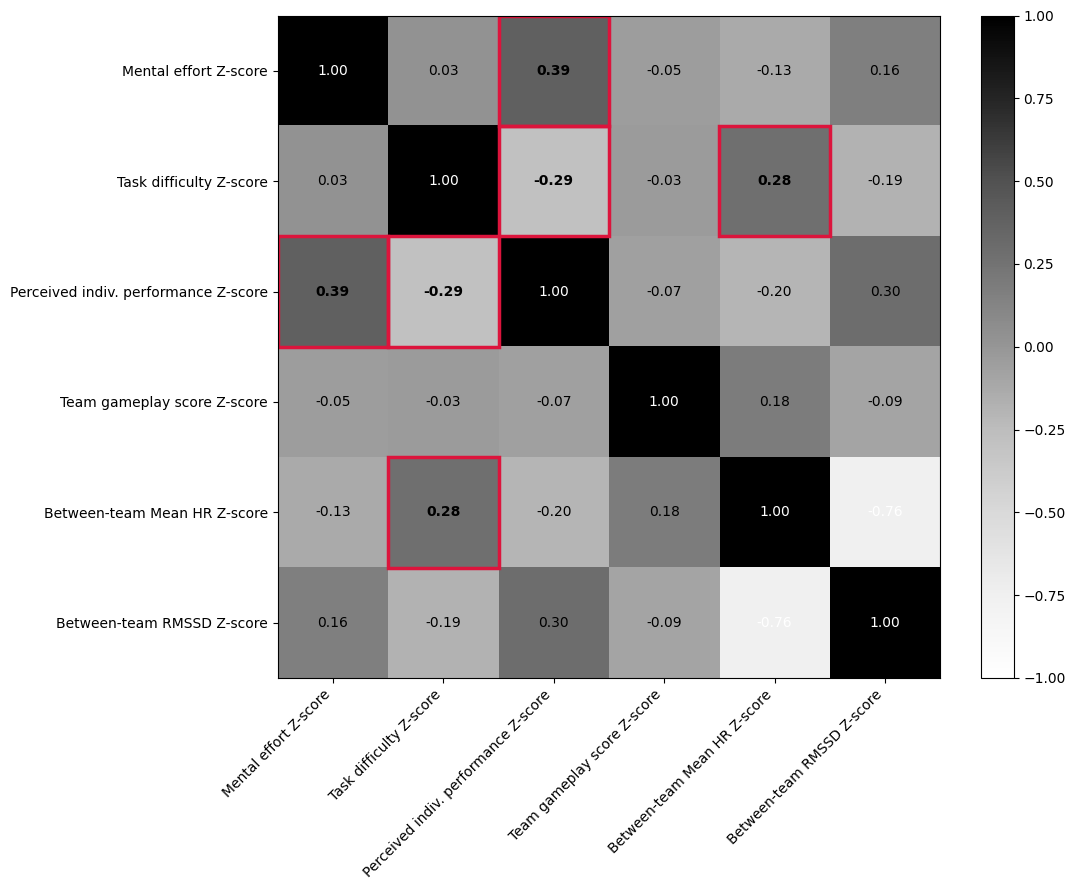

In [17]:
# Correlation matrix
corr = eda_df[cols_between].corr()

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)

display_labels = [labels[col] for col in cols_between]

ax.set_xticks(range(len(display_labels)))
ax.set_yticks(range(len(display_labels)))
ax.set_xticklabels(display_labels, rotation=45, ha="right")
ax.set_yticklabels(display_labels)

threshold = 0.20
class MultiFocus:
    def __init__(self, items):
        self.items = set(items)
    def __eq__(self, other):
        return other in self.items

focus_var = MultiFocus(["me_z", "td_z"])

for i in range(len(cols_between)):
    for j in range(len(cols_between)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) > 0.5 else "black"
        involves_focus = focus_var in (cols_between[i], cols_between[j])
        is_strong = abs(value) >= threshold and i != j and involves_focus
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                 color=text_color, fontweight="bold" if is_strong else "normal")
        if is_strong:
            rect = patches.Rectangle((j - 0.5, i - 0.5), 1, 1,
                                       linewidth=2.5, edgecolor="crimson", facecolor="none")
            ax.add_patch(rect)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

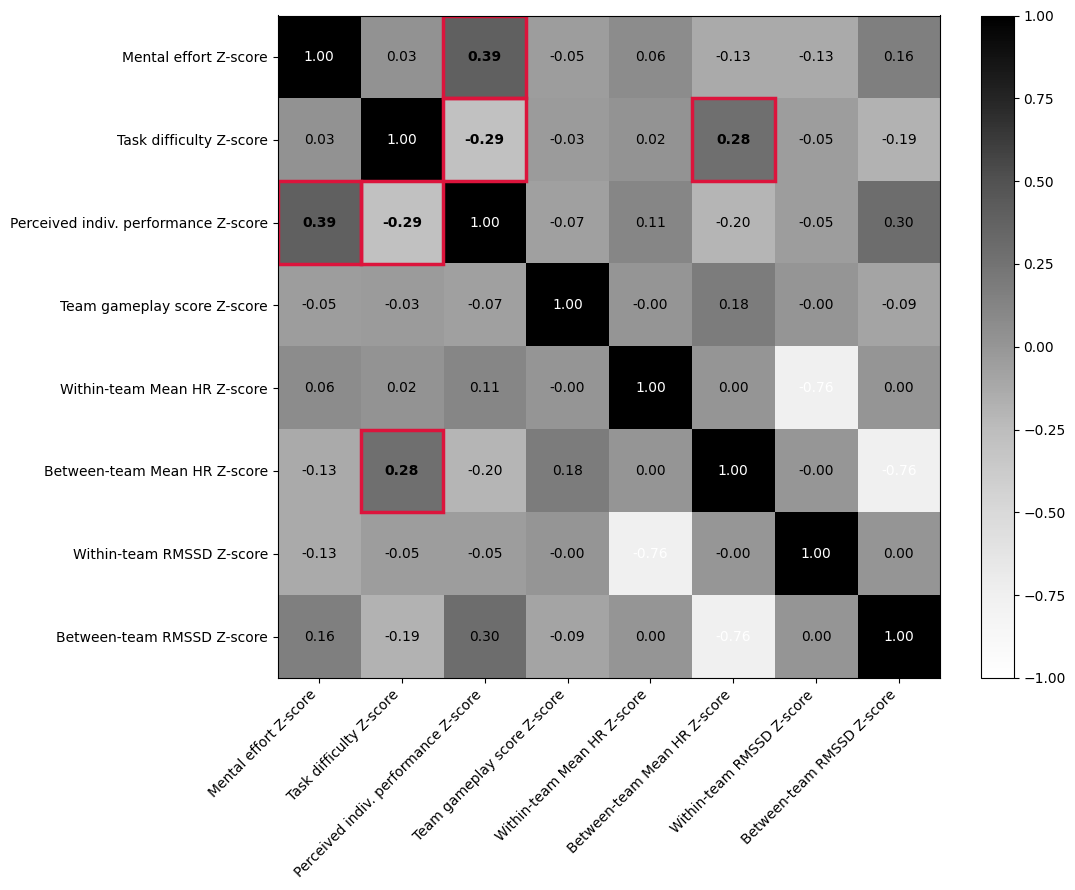

In [18]:
# Correlation matrix
corr = eda_df[cols_within_between].corr()

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)

display_labels = [labels[col] for col in cols_within_between]

ax.set_xticks(range(len(display_labels)))
ax.set_yticks(range(len(display_labels)))
ax.set_xticklabels(display_labels, rotation=45, ha="right")
ax.set_yticklabels(display_labels)

threshold = 0.20
class MultiFocus:
    def __init__(self, items):
        self.items = set(items)
    def __eq__(self, other):
        return other in self.items

focus_var = MultiFocus(["me_z", "td_z"])

for i in range(len(cols_within_between)):
    for j in range(len(cols_within_between)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) > 0.5 else "black"
        involves_focus = focus_var in (cols_within_between[i], cols_within_between[j])
        is_strong = abs(value) >= threshold and i != j and involves_focus
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                 color=text_color, fontweight="bold" if is_strong else "normal")
        if is_strong:
            rect = patches.Rectangle((j - 0.5, i - 0.5), 1, 1,
                                       linewidth=2.5, edgecolor="crimson", facecolor="none")
            ax.add_patch(rect)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [19]:
# Group ID as plain string for statsmodels MixedLM
dat_model["g"] = dat_model["groupID"].astype(str)

### Task difficulty

### Model 1: TD_Z ~ realMeanHR_bpm_z + (1|groupID)

1. Statsmodels (LME4)

In [18]:
model1_sm = sm.MixedLM.from_formula(
    "td_z ~ realMean_HR_bpm_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result1_sm = model1_sm.fit(reml=True,method="nm", maxiter=5000)
print("Model 1 sm: TD_Z ~ realMean_HR_bpm_z + (1|groupID)")
print(result1_sm.summary())

Model 1 sm: TD_Z ~ realMean_HR_bpm_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  td_z     
No. Observations:  87       Method:              REML     
No. Groups:        29       Scale:               0.9808   
Min. group size:   3        Log-Likelihood:      -124.2457
Max. group size:   3        Converged:           Yes      
Mean group size:   3.0                                    
----------------------------------------------------------
                  Coef. Std.Err.   z   P>|z| [0.025 0.975]
----------------------------------------------------------
Intercept         0.000    0.106 0.000 1.000 -0.208  0.208
realMean_HR_bpm_z 0.175    0.113 1.555 0.120 -0.046  0.396
g Var             0.000    0.115                          



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


2. Bambi (Robustness testing)

In [19]:
model1_bmb = bmb.Model(
    "td_z ~ realMean_HR_bpm_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model1 = model1_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 1 bmb: TD_Z ~ realMean_HR_bpm_z + (1|groupID)")
az.summary(idata_model1, var_names=["realMean_HR_bpm_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, realMean_HR_bpm_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


Model 1 bmb: TD_Z ~ realMean_HR_bpm_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
realMean_HR_bpm_z,0.158,0.110,-0.050,0.364,0.001,0.001,8729.0,4329.0,1.0
1|groupID_sigma,0.218,0.146,0.000,0.468,0.003,0.002,3022.0,3817.0,1.0
sigma,0.981,0.081,0.835,1.134,0.001,0.001,7221.0,3674.0,1.0


#### Within/Between Model 1: TD_Z ~ hr_between_z + hr_within_z + (1|groupID)

1. Statsmodels (LME4)

In [20]:
model1_within_sm = sm.MixedLM.from_formula(
    "td_z ~ hr_within_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result1_within_sm = model1_within_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 1 within sm: TD_Z ~ hr_within_z + (1|groupID)")
print(result1_within_sm.summary())

Model 1 within sm: TD_Z ~ hr_within_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: td_z     
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              0.9697   
Min. group size:  3       Log-Likelihood:     -125.4800
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
               Coef. Std.Err.   z   P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept      0.000    0.112 0.000 1.000 -0.220  0.220
hr_within_z    0.019    0.106 0.180 0.857 -0.189  0.227
g Var          0.042    0.121                          



In [21]:
model1_between_sm = sm.MixedLM.from_formula(
    "td_z ~ hr_between_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result1_between_sm = model1_between_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 1 between sm: TD_Z ~ hr_between_z + (1|groupID)")
print(result1_between_sm.summary())

Model 1 between sm: TD_Z ~ hr_between_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: td_z     
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              0.9333   
Min. group size:  3       Log-Likelihood:     -122.1372
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
               Coef. Std.Err.   z   P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept      0.000    0.104 0.000 1.000 -0.203  0.203
hr_between_z   0.278    0.104 2.673 0.008  0.074  0.483
g Var          0.000    0.111                          



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


In [22]:
model1_within_between_sm = sm.MixedLM.from_formula(
    "td_z ~ hr_within_z + hr_between_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result1_within_between_sm = model1_within_between_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 1 within-between sm: TD_Z ~ hr_within_z + hr_between_z + (1|groupID)")
print(result1_within_between_sm.summary())

Model 1 within-between sm: TD_Z ~ hr_within_z + hr_between_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: td_z     
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              0.9441   
Min. group size:  3       Log-Likelihood:     -123.4604
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
               Coef. Std.Err.   z   P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept      0.000    0.104 0.000 1.000 -0.204  0.204
hr_within_z    0.019    0.105 0.182 0.855 -0.186  0.224
hr_between_z   0.278    0.105 2.658 0.008  0.073  0.484
g Var          0.000    0.114                          



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


2. Bambi (Robustness testing)

In [23]:
model1_within_bmb  = bmb.Model(
    "td_z ~ hr_within_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model1_within_bmb = model1_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 1 within bmb: TD_Z ~ hr_within_z + (1|groupID)")
az.summary(idata_model1_within_bmb, var_names=["hr_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, hr_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 7 divergences after tuning. Increase `target_accept` or reparameterize.


Model 1 within bmb: TD_Z ~ hr_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
hr_within_z,0.020,0.108,-0.192,0.214,0.001,0.001,8316.0,4799.0,1.0
1|groupID_sigma,0.249,0.158,0.000,0.507,0.003,0.002,2139.0,3532.0,1.0
sigma,0.988,0.085,0.836,1.151,0.001,0.001,4278.0,2539.0,1.0


In [24]:
model1_between_bmb  = bmb.Model(
    "td_z ~ hr_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model1_between_bmb = model1_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 1 between bmb: TD_Z ~ hr_between_z + (1|groupID)")
az.summary(idata_model1_between_bmb, var_names=["hr_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, hr_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 3 seconds.


Model 1 between bmb: TD_Z ~ hr_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
hr_between_z,0.278,0.114,0.064,0.495,0.001,0.001,9250.0,5678.0,1.0
1|groupID_sigma,0.204,0.139,0.000,0.443,0.003,0.001,2316.0,2946.0,1.0
sigma,0.960,0.078,0.813,1.107,0.001,0.001,8312.0,5714.0,1.0


In [25]:
model1_within_between_bmb  = bmb.Model(
    "td_z ~ hr_within_z + hr_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model1_within_between_bmb = model1_within_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 1 within-between bmb: TD_Z ~ hr_within_z + hr_between_z + (1|groupID)")
az.summary(idata_model1_within_between_bmb, var_names=["hr_within_z", "hr_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, hr_within_z, hr_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 3 seconds.


Model 1 within-between bmb: TD_Z ~ hr_within_z + hr_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
hr_within_z,0.019,0.105,-0.182,0.210,0.001,0.001,12993.0,6042.0,1.0
hr_between_z,0.277,0.113,0.063,0.487,0.001,0.001,8427.0,6006.0,1.0
1|groupID_sigma,0.197,0.136,0.000,0.434,0.003,0.001,2643.0,3068.0,1.0
sigma,0.966,0.077,0.827,1.112,0.001,0.001,7607.0,5667.0,1.0


### Model 2: TD_Z ~ realMeanRMSSD_bpm_z + (1|groupID)

1. Statsmodels (LME4)

In [26]:
model2_sm = sm.MixedLM.from_formula(
    "td_z ~ realRMSSD_ms_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result2_sm = model2_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 2 sm: TD_Z ~ realRMSSD_ms_z + (1|groupID)")
print(result2_sm.summary())

Model 2 sm: TD_Z ~ realRMSSD_ms_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: td_z     
No. Observations:   87      Method:             REML     
No. Groups:         29      Scale:              0.9671   
Min. group size:    3       Log-Likelihood:     -124.5453
Max. group size:    3       Converged:          Yes      
Mean group size:    3.0                                  
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept       0.000    0.109  0.000 1.000 -0.213  0.213
realRMSSD_ms_z -0.149    0.109 -1.370 0.171 -0.362  0.064
g Var           0.022    0.115                           



2. Bambi (Robustness testing)

In [27]:
model2_bmb = bmb.Model(
    "td_z ~ realRMSSD_ms_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model2 = model2_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 2 bmb: TD_Z ~ realRMSSD_ms_z + (1|groupID)")
az.summary(idata_model2, var_names=["realRMSSD_ms_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, realRMSSD_ms_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


Model 2 bmb: TD_Z ~ realRMSSD_ms_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
realRMSSD_ms_z,-0.143,0.111,-0.349,0.070,0.001,0.001,10239.0,5496.0,1.0
1|groupID_sigma,0.232,0.150,0.000,0.480,0.003,0.002,2564.0,4206.0,1.0
sigma,0.980,0.081,0.830,1.135,0.001,0.001,6299.0,3904.0,1.0


#### Within/Between Model 2: TD_Z ~ rmssd_between_z + rmssd_within_z + (1|groupID)

1. Statsmodels (LME4)

In [28]:
model2_within_sm = sm.MixedLM.from_formula(
    "td_z ~ rmssd_within_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result2_within_sm = model2_within_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 2 within sm: TD_Z ~ rmssd_within_z + (1|groupID)")
print(result2_within_sm.summary())

Model 2 within sm: TD_Z ~ rmssd_within_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: td_z     
No. Observations:   87      Method:             REML     
No. Groups:         29      Scale:              0.9661   
Min. group size:    3       Log-Likelihood:     -125.3717
Max. group size:    3       Converged:          Yes      
Mean group size:    3.0                                  
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept       0.000    0.112  0.000 1.000 -0.220  0.220
rmssd_within_z -0.053    0.106 -0.499 0.617 -0.261  0.155
g Var           0.043    0.121                           



In [29]:
model2_between_sm = sm.MixedLM.from_formula(
    "td_z ~ rmssd_between_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result2_between_sm = model2_between_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 2 between sm: TD_Z ~ rmssd_between_z + (1|groupID)")
print(result2_between_sm.summary())

Model 2 between sm: TD_Z ~ rmssd_between_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  td_z     
No. Observations:  87       Method:              REML     
No. Groups:        29       Scale:               0.9536   
Min. group size:   3        Log-Likelihood:      -124.0521
Max. group size:   3        Converged:           Yes      
Mean group size:   3.0                                    
----------------------------------------------------------
                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------
Intercept        0.000    0.109  0.000 1.000 -0.213  0.213
rmssd_between_z -0.186    0.109 -1.698 0.090 -0.400  0.029
g Var            0.025    0.116                           



In [30]:
model2_within_between_sm = sm.MixedLM.from_formula(
    "td_z ~ rmssd_within_z + rmssd_between_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result2_within_between_sm = model2_within_between_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 2 within-between sm: TD_Z ~ rmssd_within_z + rmssd_between_z + (1|groupID)")
print(result2_within_between_sm.summary())

Model 2 within-between sm: TD_Z ~ rmssd_within_z + rmssd_between_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  td_z     
No. Observations:  87       Method:              REML     
No. Groups:        29       Scale:               0.9661   
Min. group size:   3        Log-Likelihood:      -125.2554
Max. group size:   3        Converged:           Yes      
Mean group size:   3.0                                    
----------------------------------------------------------
                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------
Intercept        0.000    0.109  0.000 1.000 -0.213  0.213
rmssd_within_z  -0.053    0.106 -0.499 0.617 -0.261  0.155
rmssd_between_z -0.186    0.109 -1.698 0.090 -0.400  0.029
g Var            0.020    0.115                           



2. Bambi (Robustness testing)

In [31]:
model2_within_bmb  = bmb.Model(
    "td_z ~ rmssd_within_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model2_within_bmb = model2_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 2 within bmb: TD_Z ~ rmssd_within_z + (1|groupID)")
az.summary(idata_model2_within_bmb, var_names=["rmssd_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, rmssd_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 14 divergences after tuning. Increase `target_accept` or reparameterize.


Model 2 within bmb: TD_Z ~ rmssd_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
rmssd_within_z,-0.053,0.108,-0.269,0.140,0.001,0.001,8667.0,4626.0,1.0
1|groupID_sigma,0.254,0.159,0.000,0.519,0.004,0.002,1990.0,3526.0,1.0
sigma,0.983,0.082,0.827,1.132,0.001,0.001,3746.0,3354.0,1.0


In [32]:
model2_between_bmb  = bmb.Model(
    "td_z ~ rmssd_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model2_between_bmb = model2_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 2 between bmb: TD_Z ~ rmssd_between_z + (1|groupID)")
az.summary(idata_model2_between_bmb, var_names=["rmssd_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, rmssd_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.


Model 2 between bmb: TD_Z ~ rmssd_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
rmssd_between_z,-0.187,0.118,-0.411,0.029,0.001,0.001,8603.0,6062.0,1.0
1|groupID_sigma,0.230,0.151,0.000,0.487,0.003,0.001,2115.0,2389.0,1.0
sigma,0.975,0.079,0.828,1.121,0.001,0.001,7176.0,6103.0,1.0


In [33]:
model2_within_between_bmb  = bmb.Model(
    "td_z ~ rmssd_within_z + rmssd_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model2_within_between_bmb = model2_within_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 2 within-between bmb: TD_Z ~ rmssd_within_z + rmssd_between_z + (1|groupID)")
az.summary(idata_model2_within_between_bmb, var_names=["rmssd_within_z", "rmssd_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, rmssd_within_z, rmssd_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.


Model 2 within-between bmb: TD_Z ~ rmssd_within_z + rmssd_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
rmssd_within_z,-0.051,0.107,-0.256,0.144,0.001,0.001,12048.0,5718.0,1.0
rmssd_between_z,-0.186,0.118,-0.410,0.030,0.001,0.001,9621.0,5823.0,1.0
1|groupID_sigma,0.230,0.152,0.000,0.494,0.003,0.001,1900.0,2410.0,1.0
sigma,0.979,0.081,0.830,1.132,0.001,0.001,5913.0,5291.0,1.0


### Mental effort

### Model 7: ME_Z ~ realMeanHR_bpm_z + (1|groupID)

1. Statsmodels (LME4)

In [34]:
model7_sm = sm.MixedLM.from_formula(
    "me_z ~ realMean_HR_bpm_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result7_sm = model7_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 7 sm: ME_Z ~ realMean_HR_bpm_z + (1|groupID)")
print(result7_sm.summary())

Model 7 sm: ME_Z ~ realMean_HR_bpm_z + (1|groupID)
           Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  me_z     
No. Observations:    87       Method:              REML     
No. Groups:          29       Scale:               1.0114   
Min. group size:     3        Log-Likelihood:      -125.5497
Max. group size:     3        Converged:           Yes      
Mean group size:     3.0                                    
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept         -0.000    0.108 -0.000 1.000 -0.211  0.211
realMean_HR_bpm_z -0.020    0.111 -0.182 0.856 -0.238  0.197
g Var              0.000    0.120                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


2. Bambi (Robustness testing)

In [35]:
model7_bmb = bmb.Model(
    "me_z ~ realMean_HR_bpm_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model7 = model7_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 7 bmb: ME_Z ~ realMean_HR_bpm_z + (1|groupID)")
az.summary(idata_model7, var_names=["realMean_HR_bpm_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, realMean_HR_bpm_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 6 divergences after tuning. Increase `target_accept` or reparameterize.


Model 7 bmb: ME_Z ~ realMean_HR_bpm_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
realMean_HR_bpm_z,-0.010,0.113,-0.217,0.214,0.001,0.001,9216.0,5506.0,1.0
1|groupID_sigma,0.203,0.141,0.000,0.444,0.003,0.002,2812.0,3666.0,1.0
sigma,1.000,0.082,0.848,1.148,0.001,0.001,6882.0,4616.0,1.0


#### Within/Between Model 7: ME_Z ~ hr_between_z + hr_within_z + (1|groupID)

1. Statsmodels (LME4)

In [36]:
model7_within_sm = sm.MixedLM.from_formula(
    "me_z ~ hr_within_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result7_within_sm = model7_within_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 7 within sm: ME_Z ~ hr_within_z + (1|groupID)")
print(result7_within_sm.summary())

Model 7 within sm: ME_Z ~ hr_within_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: me_z     
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              1.0077   
Min. group size:  3       Log-Likelihood:     -125.3946
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
               Coef. Std.Err.   z   P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept      0.000    0.108 0.000 1.000 -0.211  0.211
hr_within_z    0.064    0.108 0.588 0.557 -0.149  0.276
g Var          0.000    0.117                          



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


In [37]:
model7_between_sm = sm.MixedLM.from_formula(
    "me_z ~ hr_between_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result7_between_sm = model7_between_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 7 between sm: ME_Z ~ hr_between_z + (1|groupID)")
print(result7_between_sm.summary())

Model 7 between sm: ME_Z ~ hr_between_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: me_z     
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              0.9956   
Min. group size:  3       Log-Likelihood:     -124.8823
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept    -0.000    0.107 -0.000 1.000 -0.210  0.210
hr_between_z -0.126    0.108 -1.175 0.240 -0.337  0.084
g Var         0.000    0.118                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


In [38]:
model7_within_between_sm = sm.MixedLM.from_formula(
    "me_z ~ hr_within_z + hr_between_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result7_within_between_sm = model7_within_between_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 7 within-between sm: ME_Z ~ hr_within_z + hr_between_z + (1|groupID)")
print(result7_within_between_sm.summary())

Model 7 within-between sm: ME_Z ~ hr_within_z + hr_between_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: me_z     
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              1.0033   
Min. group size:  3       Log-Likelihood:     -126.0167
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept    -0.000    0.107 -0.000 1.000 -0.210  0.210
hr_within_z   0.064    0.108  0.589 0.556 -0.148  0.275
hr_between_z -0.126    0.108 -1.170 0.242 -0.338  0.085
g Var         0.000    0.120                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


2. Bambi (Robustness testing)

In [39]:
model7_within_bmb  = bmb.Model(
    "me_z ~ hr_within_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model7_within_bmb = model7_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 7 within bmb: ME_Z ~ hr_within_z + (1|groupID)")
az.summary(idata_model7_within_bmb, var_names=["hr_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, hr_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 2 divergences after tuning. Increase `target_accept` or reparameterize.


Model 7 within bmb: ME_Z ~ hr_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
hr_within_z,0.063,0.108,-0.136,0.265,0.001,0.002,8733.0,4514.0,1.0
1|groupID_sigma,0.201,0.139,0.000,0.442,0.003,0.002,2558.0,3464.0,1.0
sigma,0.996,0.081,0.845,1.150,0.001,0.001,6152.0,4129.0,1.0


In [40]:
model7_between_bmb  = bmb.Model(
    "me_z ~ hr_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model7_between_bmb = model7_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 7 between bmb: ME_Z ~ hr_between_z + (1|groupID)")
az.summary(idata_model7_between_bmb, var_names=["hr_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, hr_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 3 seconds.


Model 7 between bmb: ME_Z ~ hr_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
hr_between_z,-0.127,0.117,-0.337,0.104,0.001,0.001,9436.0,5805.0,1.0
1|groupID_sigma,0.200,0.138,0.000,0.437,0.003,0.001,2590.0,2686.0,1.0
sigma,0.992,0.080,0.843,1.137,0.001,0.001,9123.0,5413.0,1.0


In [41]:
model7_within_between_bmb  = bmb.Model(
    "me_z ~ hr_within_z + hr_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model7_within_between_bmb = model7_within_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 7 within-between bmb: ME_Z ~ hr_within_z + hr_between_z + (1|groupID)")
az.summary(idata_model7_within_between_bmb, var_names=["hr_within_z", "hr_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, hr_within_z, hr_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 3 seconds.


Model 7 within-between bmb: ME_Z ~ hr_within_z + hr_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
hr_within_z,0.065,0.109,-0.145,0.261,0.001,0.001,12967.0,6049.0,1.0
hr_between_z,-0.126,0.119,-0.340,0.100,0.001,0.001,8571.0,5697.0,1.0
1|groupID_sigma,0.199,0.141,0.000,0.446,0.003,0.001,2596.0,3029.0,1.0
sigma,0.998,0.081,0.846,1.146,0.001,0.001,8201.0,5847.0,1.0


### Model 8: ME_Z ~ realMeanRMSSD_bpm_z + (1|groupID)

1. Statsmodels (LME4)

In [42]:
model8_sm = sm.MixedLM.from_formula(
    "me_z ~ realRMSSD_ms_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result8_sm = model8_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 8 sm: ME_Z ~ realRMSSD_ms_z + (1|groupID)")
print(result8_sm.summary())

Model 8 sm: ME_Z ~ realRMSSD_ms_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: me_z     
No. Observations:   87      Method:             REML     
No. Groups:         29      Scale:              1.0117   
Min. group size:    3       Log-Likelihood:     -125.5632
Max. group size:    3       Converged:          Yes      
Mean group size:    3.0                                  
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept      -0.000    0.108 -0.000 1.000 -0.211  0.211
realRMSSD_ms_z -0.009    0.114 -0.082 0.934 -0.233  0.214
g Var           0.000    0.121                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


2. Bambi (Robustness testing)

In [43]:
model8_bmb = bmb.Model(
    "me_z ~ realRMSSD_ms_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model8 = model8_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 8 bmb: ME_Z ~ realRMSSD_ms_z + (1|groupID)")
az.summary(idata_model8, var_names=["realRMSSD_ms_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, realRMSSD_ms_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


Model 8 bmb: ME_Z ~ realRMSSD_ms_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
realRMSSD_ms_z,-0.026,0.116,-0.239,0.190,0.001,0.002,10401.0,4737.0,1.0
1|groupID_sigma,0.209,0.144,0.000,0.459,0.003,0.002,3225.0,4078.0,1.0
sigma,0.998,0.081,0.843,1.145,0.001,0.001,6836.0,3784.0,1.0


#### Within/Between Model 8: ME_Z ~ rmssd_between_z + rmssd_within_z + (1|groupID)

1. Statsmodels (LME4)

In [44]:
model8_within_sm = sm.MixedLM.from_formula(
    "me_z ~ rmssd_within_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result8_within_sm = model8_within_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 8 within sm: ME_Z ~ rmssd_within_z + (1|groupID)")
print(result8_within_sm.summary())

Model 8 within sm: ME_Z ~ rmssd_within_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: me_z     
No. Observations:   87      Method:             REML     
No. Groups:         29      Scale:              0.9953   
Min. group size:    3       Log-Likelihood:     -124.8678
Max. group size:    3       Converged:          Yes      
Mean group size:    3.0                                  
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept      -0.000    0.107 -0.000 1.000 -0.210  0.210
rmssd_within_z -0.128    0.108 -1.187 0.235 -0.339  0.083
g Var           0.000    0.115                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


In [45]:
model8_between_sm = sm.MixedLM.from_formula(
    "me_z ~ rmssd_between_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result8_between_sm = model8_between_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 8 between sm: ME_Z ~ rmssd_between_z + (1|groupID)")
print(result8_between_sm.summary())

/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Model 8 between sm: ME_Z ~ rmssd_between_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  me_z     
No. Observations:  87       Method:              REML     
No. Groups:        29       Scale:               0.9866   
Min. group size:   3        Log-Likelihood:      -124.4981
Max. group size:   3        Converged:           Yes      
Mean group size:   3.0                                    
----------------------------------------------------------
                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------
Intercept       -0.000    0.106 -0.000 1.000 -0.209  0.209
rmssd_between_z  0.158    0.107  1.471 0.141 -0.052  0.368
g Var            0.000    0.120                           



In [46]:
model8_within_between_sm = sm.MixedLM.from_formula(
    "me_z ~ rmssd_within_z + rmssd_between_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result8_within_between_sm = model8_within_between_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 8 within-between sm: ME_Z ~ rmssd_within_z + rmssd_between_z + (1|groupID)")
print(result8_within_between_sm.summary())

Model 8 within-between sm: ME_Z ~ rmssd_within_z + rmssd_between_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  me_z     
No. Observations:  87       Method:              REML     
No. Groups:        29       Scale:               0.9817   
Min. group size:   3        Log-Likelihood:      -125.1014
Max. group size:   3        Converged:           Yes      
Mean group size:   3.0                                    
----------------------------------------------------------
                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------
Intercept       -0.000    0.106 -0.000 1.000 -0.208  0.208
rmssd_within_z  -0.128    0.107 -1.196 0.232 -0.337  0.082
rmssd_between_z  0.158    0.107  1.475 0.140 -0.052  0.367
g Var            0.000    0.120                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


2. Bambi (Robustness testing)

In [47]:
model8_within_bmb  = bmb.Model(
    "me_z ~ rmssd_within_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model8_within_bmb = model8_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 8 within bmb: ME_Z ~ rmssd_within_z + (1|groupID)")
az.summary(idata_model8_within_bmb, var_names=["rmssd_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, rmssd_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 4 divergences after tuning. Increase `target_accept` or reparameterize.


Model 8 within bmb: ME_Z ~ rmssd_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
rmssd_within_z,-0.127,0.109,-0.332,0.082,0.001,0.002,10640.0,4786.0,1.0
1|groupID_sigma,0.202,0.139,0.000,0.442,0.002,0.001,3017.0,4006.0,1.0
sigma,0.991,0.079,0.842,1.137,0.001,0.001,7464.0,4230.0,1.0


In [48]:
model8_between_bmb  = bmb.Model(
    "me_z ~ rmssd_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model8_between_bmb = model8_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 8 between bmb: ME_Z ~ rmssd_between_z + (1|groupID)")
az.summary(idata_model8_between_bmb, var_names=["rmssd_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, rmssd_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 3 seconds.


Model 8 between bmb: ME_Z ~ rmssd_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
rmssd_between_z,0.159,0.118,-0.056,0.391,0.001,0.001,10766.0,5998.0,1.0
1|groupID_sigma,0.198,0.136,0.000,0.432,0.002,0.001,2783.0,2936.0,1.0
sigma,0.988,0.079,0.842,1.136,0.001,0.001,9996.0,5900.0,1.0


In [49]:
model8_within_between_bmb  = bmb.Model(
    "me_z ~ rmssd_within_z + rmssd_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model8_within_between_bmb = model8_within_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 8 within-between bmb: ME_Z ~ rmssd_within_z + rmssd_between_z + (1|groupID)")
az.summary(idata_model8_within_between_bmb, var_names=["rmssd_within_z", "rmssd_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, rmssd_within_z, rmssd_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 3 seconds.


Model 8 within-between bmb: ME_Z ~ rmssd_within_z + rmssd_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
rmssd_within_z,-0.128,0.104,-0.329,0.067,0.001,0.001,14063.0,6105.0,1.0
rmssd_between_z,0.157,0.117,-0.057,0.381,0.001,0.001,11667.0,6192.0,1.0
1|groupID_sigma,0.200,0.137,0.000,0.439,0.002,0.001,2782.0,3039.0,1.0
sigma,0.986,0.080,0.837,1.131,0.001,0.001,9784.0,5958.0,1.0


### Performance

### Model 14: PP_Z ~ realMeanHR_bpm_z + (1|groupID)

1. Statsmodels (LME4)

In [50]:
model14_sm = sm.MixedLM.from_formula(
    "pp_z ~ realMean_HR_bpm_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result14_sm = model14_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 14 sm: PP_Z ~ realMean_HR_bpm_z + (1|groupID)")
print(result14_sm.summary())

Model 14 sm: PP_Z ~ realMean_HR_bpm_z + (1|groupID)
           Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  pp_z     
No. Observations:    87       Method:              REML     
No. Groups:          29       Scale:               0.7763   
Min. group size:     3        Log-Likelihood:      -123.5054
Max. group size:     3        Converged:           Yes      
Mean group size:     3.0                                    
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept         -0.000    0.132 -0.000 1.000 -0.258  0.258
realMean_HR_bpm_z  0.041    0.107  0.388 0.698 -0.168  0.251
g Var              0.243    0.191                           



2. Bambi (Robustness testing)

In [51]:
model14_bmb = bmb.Model(
    "pp_z ~ realMean_HR_bpm_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model14 = model14_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 14 bmb: PP_Z ~ realMean_HR_bpm_z + (1|groupID)")
az.summary(idata_model14, var_names=["realMean_HR_bpm_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, realMean_HR_bpm_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 5 divergences after tuning. Increase `target_accept` or reparameterize.


Model 14 bmb: PP_Z ~ realMean_HR_bpm_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
realMean_HR_bpm_z,0.036,0.109,-0.171,0.236,0.002,0.001,5166.0,4753.0,1.0
1|groupID_sigma,0.472,0.183,0.115,0.834,0.005,0.003,1629.0,2249.0,1.0
sigma,0.907,0.088,0.747,1.071,0.002,0.001,2670.0,3436.0,1.0


#### Within/Between Model 14: PP_Z ~ hr_between_z + hr_within_z + (1|groupID)

1. Statsmodels (LME4)

In [52]:
model14_within_sm = sm.MixedLM.from_formula(
    "pp_z ~ hr_within_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result14_within_sm = model14_within_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 14 within sm: PP_Z ~ hr_within_z + (1|groupID)")
print(result14_within_sm.summary())

Model 14 within sm: PP_Z ~ hr_within_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: pp_z     
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              0.7695   
Min. group size:  3       Log-Likelihood:     -122.9537
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept    -0.000    0.130 -0.000 1.000 -0.254  0.254
hr_within_z   0.113    0.095  1.198 0.231 -0.072  0.299
g Var         0.232    0.182                           



In [53]:
model14_between_sm = sm.MixedLM.from_formula(
    "pp_z ~ hr_between_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result14_between_sm = model14_between_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 14 between sm: PP_Z ~ hr_between_z + (1|groupID)")
print(result14_between_sm.summary())

Model 14 between sm: PP_Z ~ hr_between_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: pp_z     
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              0.7753   
Min. group size:  3       Log-Likelihood:     -122.1915
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept    -0.000    0.127 -0.000 1.000 -0.248  0.248
hr_between_z -0.197    0.127 -1.548 0.122 -0.447  0.052
g Var         0.207    0.174                           



In [54]:
model14_within_between_sm = sm.MixedLM.from_formula(
    "pp_z ~ hr_within_z + hr_between_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result14_within_between_sm = model14_within_between_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 14 within-between sm: PP_Z ~ hr_within_z + hr_between_z + (1|groupID)")
print(result14_within_between_sm.summary())

Model 14 within-between sm: PP_Z ~ hr_within_z + hr_between_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: pp_z     
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              0.7695   
Min. group size:  3       Log-Likelihood:     -122.9138
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept    -0.000    0.127 -0.000 1.000 -0.248  0.248
hr_within_z   0.113    0.095  1.198 0.231 -0.072  0.299
hr_between_z -0.197    0.127 -1.548 0.122 -0.447  0.052
g Var         0.209    0.175                           



2. Bambi (Robustness testing)

In [55]:
model14_within_bmb  = bmb.Model(
    "pp_z ~ hr_within_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model14_within_bmb = model14_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 14 within bmb: PP_Z ~ hr_within_z + (1|groupID)")
az.summary(idata_model14_within_bmb, var_names=["hr_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, hr_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


Model 14 within bmb: PP_Z ~ hr_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
hr_within_z,0.114,0.098,-0.078,0.292,0.001,0.001,8723.0,5489.0,1.0
1|groupID_sigma,0.467,0.171,0.135,0.810,0.004,0.002,1749.0,2481.0,1.0
sigma,0.900,0.088,0.738,1.063,0.002,0.001,2716.0,3239.0,1.0


In [56]:
model14_between_bmb  = bmb.Model(
    "pp_z ~ hr_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model14_between_bmb = model14_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 14 between bmb: PP_Z ~ hr_between_z + (1|groupID)")
az.summary(idata_model14_between_bmb, var_names=["hr_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, hr_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.


Model 14 between bmb: PP_Z ~ hr_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
hr_between_z,-0.195,0.132,-0.457,0.049,0.002,0.002,5356.0,5331.0,1.0
1|groupID_sigma,0.430,0.182,0.053,0.749,0.005,0.003,1344.0,1162.0,1.0
sigma,0.905,0.085,0.753,1.068,0.002,0.001,2894.0,5258.0,1.0


In [57]:
model14_within_between_bmb  = bmb.Model(
    "pp_z ~ hr_within_z + hr_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model14_within_between_bmb = model14_within_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 14 within-between bmb: PP_Z ~ hr_within_z + hr_between_z + (1|groupID)")
az.summary(idata_model14_within_between_bmb, var_names=["hr_within_z", "hr_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, hr_within_z, hr_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.


Model 14 within-between bmb: PP_Z ~ hr_within_z + hr_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
hr_within_z,0.113,0.097,-0.073,0.291,0.001,0.001,9624.0,6042.0,1.0
hr_between_z,-0.194,0.131,-0.438,0.052,0.002,0.002,4866.0,5222.0,1.0
1|groupID_sigma,0.429,0.183,0.037,0.730,0.005,0.003,1455.0,1684.0,1.0
sigma,0.904,0.087,0.739,1.062,0.002,0.001,2840.0,4273.0,1.0


### Model 15: PP_Z ~ realMeanRMSSD_bpm_z + (1|groupID)

1. Statsmodels (LME4)

In [58]:
model15_sm = sm.MixedLM.from_formula(
    "pp_z ~ realRMSSD_ms_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result15_sm = model15_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 15 sm: PP_Z ~ realRMSSD_ms_z + (1|groupID)")
print(result15_sm.summary())

Model 15 sm: PP_Z ~ realRMSSD_ms_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: pp_z     
No. Observations:   87      Method:             REML     
No. Groups:         29      Scale:              0.7988   
Min. group size:    3       Log-Likelihood:     -123.3808
Max. group size:    3       Converged:          Yes      
Mean group size:    3.0                                  
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept      -0.000    0.127 -0.000 1.000 -0.249  0.249
realRMSSD_ms_z  0.068    0.110  0.619 0.536 -0.148  0.284
g Var           0.203    0.180                           



2. Bambi (Robustness testing)

In [59]:
model15_bmb = bmb.Model(
    "pp_z ~ realRMSSD_ms_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model15 = model15_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 15 bmb: PP_Z ~ realRMSSD_ms_z + (1|groupID)")
az.summary(idata_model15, var_names=["realRMSSD_ms_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, realRMSSD_ms_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.


Model 15 bmb: PP_Z ~ realRMSSD_ms_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
realRMSSD_ms_z,0.076,0.111,-0.134,0.283,0.001,0.001,6300.0,5135.0,1.0
1|groupID_sigma,0.417,0.184,0.000,0.689,0.005,0.003,1309.0,1221.0,1.0
sigma,0.920,0.088,0.759,1.087,0.002,0.001,3230.0,4985.0,1.0


#### Within/Between Model 15: PP_Z ~ rmssd_between_z + rmssd_within_z + (1|groupID)

1. Statsmodels (LME4)

In [60]:
model15_within_sm = sm.MixedLM.from_formula(
    "pp_z ~ rmssd_within_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result15_within_sm = model15_within_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 15 within sm: PP_Z ~ rmssd_within_z + (1|groupID)")
print(result15_within_sm.summary())

Model 15 within sm: PP_Z ~ rmssd_within_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: pp_z     
No. Observations:   87      Method:             REML     
No. Groups:         29      Scale:              0.7849   
Min. group size:    3       Log-Likelihood:     -123.5157
Max. group size:    3       Converged:          Yes      
Mean group size:    3.0                                  
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept      -0.000    0.130 -0.000 1.000 -0.254  0.254
rmssd_within_z -0.052    0.096 -0.543 0.587 -0.239  0.135
g Var           0.227    0.180                           



In [61]:
model15_between_sm = sm.MixedLM.from_formula(
    "pp_z ~ rmssd_between_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result15_between_sm = model15_between_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 15 between sm: PP_Z ~ rmssd_between_z + (1|groupID)")
print(result15_between_sm.summary())

Model 15 between sm: PP_Z ~ rmssd_between_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  pp_z     
No. Observations:  87       Method:              REML     
No. Groups:        29       Scale:               0.7753   
Min. group size:   3        Log-Likelihood:      -120.5983
Max. group size:   3        Converged:           Yes      
Mean group size:   3.0                                    
----------------------------------------------------------
                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------
Intercept       -0.000    0.119 -0.000 1.000 -0.234  0.234
rmssd_between_z  0.296    0.120  2.466 0.014  0.061  0.531
g Var            0.155    0.155                           



In [62]:
model15_within_between_sm = sm.MixedLM.from_formula(
    "pp_z ~ rmssd_within_z + rmssd_between_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result15_within_between_sm = model15_within_between_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 15 within-between sm: PP_Z ~ rmssd_within_z + rmssd_between_z + (1|groupID)")
print(result15_within_between_sm.summary())

Model 15 within-between sm: PP_Z ~ rmssd_within_z + rmssd_between_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  pp_z     
No. Observations:  87       Method:              REML     
No. Groups:        29       Scale:               0.7849   
Min. group size:   3        Log-Likelihood:      -121.8826
Max. group size:   3        Converged:           Yes      
Mean group size:   3.0                                    
----------------------------------------------------------
                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------
Intercept       -0.000    0.119 -0.000 1.000 -0.234  0.234
rmssd_within_z  -0.052    0.096 -0.543 0.587 -0.239  0.135
rmssd_between_z  0.296    0.120  2.466 0.014  0.061  0.531
g Var            0.152    0.154                           



2. Bambi (Robustness testing)

In [63]:
model15_within_bmb  = bmb.Model(
    "pp_z ~ rmssd_within_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model15_within_bmb = model15_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 15 within bmb: PP_Z ~ rmssd_within_z + (1|groupID)")
az.summary(idata_model15_within_bmb, var_names=["rmssd_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, rmssd_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 5 divergences after tuning. Increase `target_accept` or reparameterize.


Model 15 within bmb: PP_Z ~ rmssd_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
rmssd_within_z,-0.053,0.098,-0.231,0.137,0.001,0.001,7839.0,4916.0,1.0
1|groupID_sigma,0.459,0.176,0.091,0.783,0.004,0.003,1873.0,2227.0,1.0
sigma,0.910,0.088,0.743,1.071,0.002,0.001,2997.0,3993.0,1.0


In [64]:
model15_between_bmb  = bmb.Model(
    "pp_z ~ rmssd_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model15_between_bmb = model15_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 15 between bmb: PP_Z ~ rmssd_between_z + (1|groupID)")
az.summary(idata_model15_between_bmb, var_names=["rmssd_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, rmssd_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.


Model 15 between bmb: PP_Z ~ rmssd_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
rmssd_between_z,0.295,0.124,0.053,0.518,0.002,0.002,5046.0,4751.0,1.0
1|groupID_sigma,0.372,0.173,0.001,0.635,0.004,0.002,1606.0,1867.0,1.0
sigma,0.902,0.083,0.750,1.058,0.001,0.001,3309.0,5638.0,1.0


In [65]:
model15_within_between_bmb  = bmb.Model(
    "pp_z ~ rmssd_within_z + rmssd_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model15_within_between_bmb = model15_within_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 15 within-between bmb: PP_Z ~ rmssd_within_z + rmssd_between_z + (1|groupID)")
az.summary(idata_model15_within_between_bmb, var_names=["rmssd_within_z", "rmssd_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, rmssd_within_z, rmssd_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.


Model 15 within-between bmb: PP_Z ~ rmssd_within_z + rmssd_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
rmssd_within_z,-0.052,0.098,-0.240,0.125,0.001,0.001,9529.0,5990.0,1.0
rmssd_between_z,0.296,0.123,0.065,0.527,0.002,0.001,6557.0,5693.0,1.0
1|groupID_sigma,0.364,0.174,0.007,0.637,0.004,0.002,1634.0,2311.0,1.0
sigma,0.908,0.083,0.752,1.062,0.001,0.001,3716.0,5206.0,1.0


### Model 16: PP_Z ~ me + (1|groupID)

1. Statsmodels (LME4)

In [66]:
model16_sm = sm.MixedLM.from_formula(
    "pp_z ~ me_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result16_sm = model16_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 16 sm: PP_Z ~ me_z + (1|groupID)")
print(result16_sm.summary())

Model 16 sm: PP_Z ~ me_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: pp_z     
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              0.7184   
Min. group size:  3       Log-Likelihood:     -117.5264
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
--------------------------------------------------------
           Coef.  Std.Err.    z    P>|z|  [0.025  0.975]
--------------------------------------------------------
Intercept  0.000     0.115  0.000  1.000  -0.225   0.225
me_z       0.354     0.100  3.555  0.000   0.159   0.550
g Var      0.143     0.151                              



2. Bambi (Robustness testing)

In [67]:
model16_bmb = bmb.Model(
    "pp_z ~ me_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model16 = model16_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 16 bmb: PP_Z ~ me_z + (1|groupID)")
az.summary(idata_model16, var_names=["me_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, me_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 19 divergences after tuning. Increase `target_accept` or reparameterize.


Model 16 bmb: PP_Z ~ me_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
me_z,0.357,0.101,0.169,0.550,0.001,0.001,6724.0,4630.0,1.0
1|groupID_sigma,0.348,0.168,0.001,0.603,0.004,0.002,1690.0,2609.0,1.0
sigma,0.871,0.082,0.721,1.025,0.001,0.001,3041.0,2848.0,1.0


### Model 17: PP_Z ~ td + (1|groupID)

1. Statsmodels (LME4)

In [68]:
model17_sm = sm.MixedLM.from_formula(
    "pp_z ~ td_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
result17_sm = model17_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model 17 sm: PP_Z ~ td_z + (1|groupID)")
print(result17_sm.summary())

Model 17 sm: PP_Z ~ td_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: pp_z     
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              0.7907   
Min. group size:  3       Log-Likelihood:     -121.0131
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept    -0.000    0.118 -0.000 1.000 -0.231  0.231
td_z         -0.245    0.108 -2.268 0.023 -0.456 -0.033
g Var         0.141    0.156                           



2. Bambi (Robustness testing)

In [69]:
model17_bmb = bmb.Model(
    "pp_z ~ td_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model17 = model17_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 17 bmb: PP_Z ~ td_z + (1|groupID)")
az.summary(idata_model17, var_names=["td_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, td_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 4 divergences after tuning. Increase `target_accept` or reparameterize.


Model 17 bmb: PP_Z ~ td_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
td_z,-0.248,0.108,-0.458,-0.052,0.001,0.001,6823.0,5237.0,1.0
1|groupID_sigma,0.350,0.175,0.000,0.621,0.004,0.002,1633.0,2590.0,1.0
sigma,0.910,0.084,0.758,1.070,0.001,0.001,3531.0,3572.0,1.0


### Model 18: uncertScore ~ me + (1|groupID)

1. Statsmodels (LME4)

In [76]:
# Model 18: team-level OLS (no groups, no random effect)
result18_ols = smf.ols("uncertScore_z ~ me_between_z", data=team_model).fit()
print(result18_ols.summary())

                            OLS Regression Results                            
Dep. Variable:          uncertScore_z   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                 -0.027
Method:                 Least Squares   F-statistic:                    0.2640
Date:                Fri, 25 Sep 2026   Prob (F-statistic):              0.612
Time:                        16:31:54   Log-Likelihood:                -40.841
No. Observations:                  29   AIC:                             85.68
Df Residuals:                      27   BIC:                             88.42
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept    -4.025e-16      0.190  -2.11e-15   

2. Bambi (Robustness testing)

In [ ]:
model18_bmb = bmb.Model(
    "uncertScore_z ~ me_between_z",
    data=team_model,
    family="gaussian"
)

idata_model18 = model18_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)


print("Model 18 bmb: uncertScore_z ~ me_between_z")
az.summary(idata_model18, var_names=["me_between_z", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, me_between_z]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


Model 18 bmb: uncertScore_z ~ me_between_z


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
me_between_z,-0.098,0.199,-0.454,0.307,0.002,0.002,9004.0,5645.0,1.0
sigma,1.051,0.146,0.796,1.329,0.002,0.002,7564.0,4594.0,1.0


### Model 19: uncertScore_z ~ td + (1|groupID)

1. Statsmodels (LME4)

In [74]:
result19_ols = smf.ols("uncertScore_z ~ td_between_z", data=team_model).fit()
print(result19_ols.summary())

                            OLS Regression Results                            
Dep. Variable:          uncertScore_z   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                 -0.034
Method:                 Least Squares   F-statistic:                   0.07776
Date:                Fri, 25 Sep 2026   Prob (F-statistic):              0.782
Time:                        16:31:44   Log-Likelihood:                -40.940
No. Observations:                  29   AIC:                             85.88
Df Residuals:                      27   BIC:                             88.61
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept    -4.025e-16      0.191  -2.11e-15   

2. Bambi (Robustness testing)

In [78]:
model19_bmb = bmb.Model(
    "uncertScore_z ~ td_between_z",
    data=team_model,
    family="gaussian"
)

idata_model19 = model19_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)


print("Model 19 bmb: uncertScore_z ~ td_between_z")
az.summary(idata_model19, var_names=["td_between_z", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, td_between_z]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


Model 19 bmb: uncertScore_z ~ td_between_z


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
td_between_z,-0.053,0.201,-0.454,0.300,0.002,0.002,9651.0,6004.0,1.0
sigma,1.056,0.147,0.786,1.316,0.002,0.002,7523.0,5223.0,1.0


### EXTRA

### Model 1: me_z ~ td_z + (1|groupID)

1. Statsmodels (LME4)

In [ ]:
modelEXTRA1_sm = sm.MixedLM.from_formula(
    "me_z ~ td_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
resultEXTRA1_sm = modelEXTRA1_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model EXTRA1 sm: ME_Z ~ TD_Z + (1|groupID)")
print(resultEXTRA1_sm.summary())

Model EXTRA1 sm: ME_Z ~ TD_Z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: me_z     
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              1.0108   
Min. group size:  3       Log-Likelihood:     -125.5256
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept    -0.000    0.108 -0.000 1.000 -0.211  0.211
td_z          0.031    0.111  0.281 0.778 -0.186  0.249
g Var         0.000    0.117                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


2. Bambi (Robustness testing)

In [ ]:
modelENTRA1_bmb = bmb.Model(
    "me_z ~ td_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_modelEXTRA1 = modelENTRA1_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)






print("Model EXTRA1 bmb: ME_Z ~ TD_Z + (1|groupID)")
az.summary(idata_modelEXTRA1, var_names=["td_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, td_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 7 divergences after tuning. Increase `target_accept` or reparameterize.


Model EXTRA1 bmb: ME_Z ~ TD_Z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
td_z,0.040,0.112,-0.172,0.247,0.001,0.002,9318.0,4577.0,1.0
1|groupID_sigma,0.209,0.144,0.000,0.458,0.002,0.002,3151.0,3941.0,1.0
sigma,0.997,0.080,0.854,1.155,0.001,0.001,6896.0,4470.0,1.0


### Model 2: td_z ~ me_z + (1|groupID)

1. Statsmodels (LME4)

In [ ]:
modelEXTRA2_sm = sm.MixedLM.from_formula(
    "td_z ~ me_z",
    groups="g",
    re_formula="1",
    data=dat_model
)
resultEXTRA2_sm = modelEXTRA2_sm.fit(reml=True, method="nm", maxiter=5000)
print("Model EXTRA2 sm: TD_Z ~ ME_Z + (1|groupID)")
print(resultEXTRA2_sm.summary())

Model EXTRA2 sm: TD_Z ~ ME_Z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: td_z     
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              0.9566   
Min. group size:  3       Log-Likelihood:     -125.4061
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
--------------------------------------------------------
           Coef.  Std.Err.    z    P>|z|  [0.025  0.975]
--------------------------------------------------------
Intercept  0.000     0.114  0.000  1.000  -0.223   0.223
me_z       0.041     0.110  0.377  0.706  -0.174   0.257
g Var      0.056     0.127                              



2. Bambi (Robustness testing)

In [ ]:
modelENTRA2_bmb = bmb.Model(
    "td_z ~ me_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_modelEXTRA2 = modelENTRA2_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model EXTRA2 bmb: TD_Z ~ ME_Z + (1|groupID)")
az.summary(idata_modelEXTRA2, var_names=["me_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, me_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 2 divergences after tuning. Increase `target_accept` or reparameterize.


Model EXTRA2 bmb: TD_Z ~ ME_Z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
me_z,0.046,0.110,-0.159,0.254,0.001,0.001,11942.0,5519.0,1.0
1|groupID_sigma,0.263,0.162,0.000,0.534,0.003,0.002,2233.0,3355.0,1.0
sigma,0.982,0.084,0.832,1.147,0.001,0.001,6268.0,4165.0,1.0
